In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from woody_filter import woody, woody_stochastic
import ast


In [17]:
erp_congruent = np.load('cong_erp_raw_mean.npy')
erp_incongruent = np.load('incong_erp_raw_mean.npy')
times = np.load('times.npy')

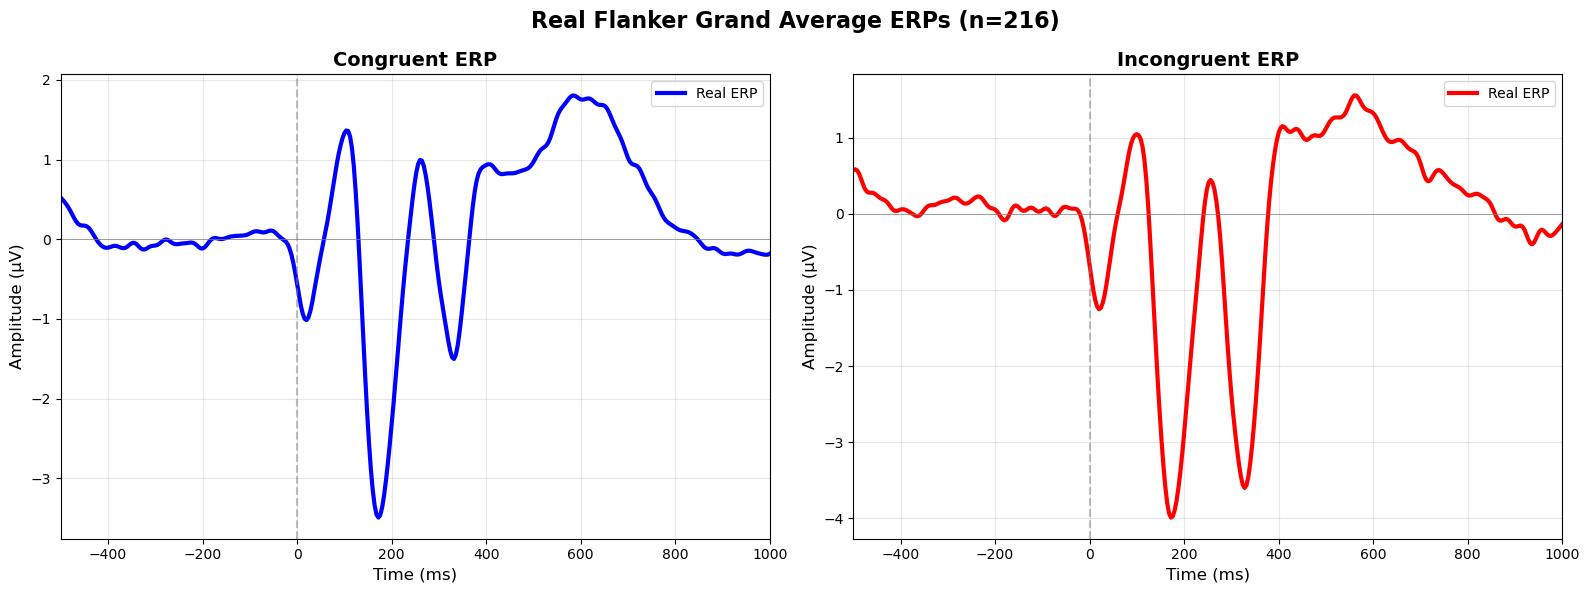

In [19]:
# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Congruent
ax1.plot(times * 1000, erp_congruent, 'b', linewidth=3, label='Real ERP')
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlim([-500, 1000])
ax1.set_xlabel('Time (ms)', fontsize=12)
ax1.set_ylabel('Amplitude (µV)', fontsize=12)
ax1.set_title('Congruent ERP', fontweight='bold', fontsize=14)
ax1.legend()
ax1.grid(alpha=0.3)

# Incongruent
ax2.plot(times * 1000, erp_incongruent, 'r', linewidth=3, label='Real ERP')
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_xlim([-500, 1000])
ax2.set_xlabel('Time (ms)', fontsize=12)
ax2.set_ylabel('Amplitude (µV)', fontsize=12)
ax2.set_title('Incongruent ERP', fontweight='bold', fontsize=14)
ax2.legend()
ax2.grid(alpha=0.3)

plt.suptitle('Real Flanker Grand Average ERPs (n=216)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


Generated 100 trials per condition
Congruent - Temporal jitter: M=-5.9ms, SD=39.7ms
Congruent - Amplitude scaling: M=0.99, SD=0.22
Incongruent - Temporal jitter: M=-2.2ms, SD=43.4ms
Incongruent - Amplitude scaling: M=0.98, SD=0.20


/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_3848/4052411068.py:168: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


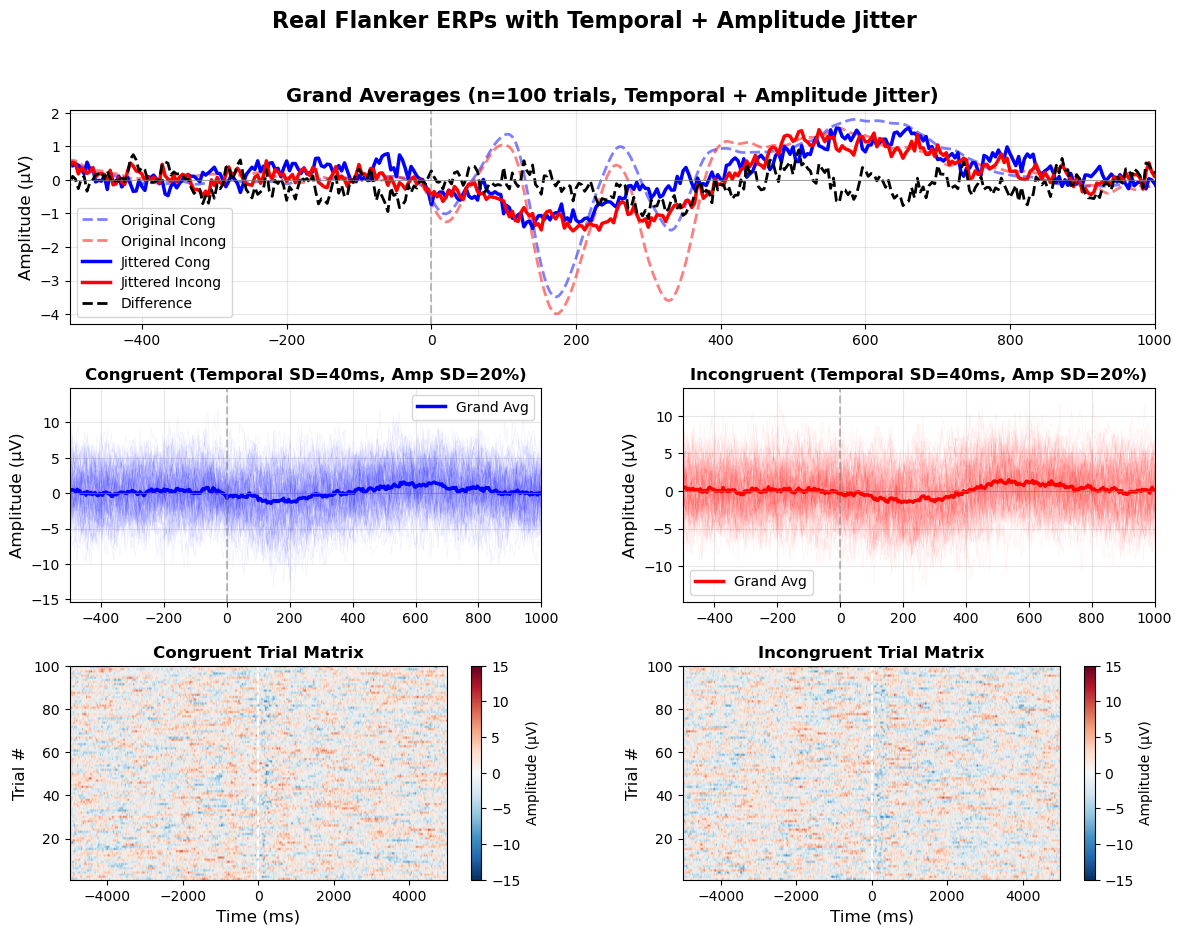

In [41]:
# SIMULATION PARAMETERS
n_trials = 100
noise_amplitude = 3.0  # µV
sfreq = 500  # Hz

# Jitter parameters (in seconds)
jitter_sd_congruent = 0.040 # 40ms SD (temporal)
jitter_sd_incongruent = 0.040  # 40ms SD (temporal)

# Amplitude jitter parameters (proportion of signal amplitude)
amplitude_jitter_congruent = 0.20  # 20% SD
amplitude_jitter_incongruent = 0.20  # 20% SD

def generate_pink_noise(n_samples):
    """Generate pink (1/f) noise"""
    white = np.random.randn(n_samples)
    fft_white = np.fft.rfft(white)
    freqs = np.fft.rfftfreq(n_samples)
    freqs[0] = 1  # Avoid division by zero
    pink_fft = fft_white / np.sqrt(freqs)
    pink = np.fft.irfft(pink_fft, n=n_samples)
    pink = pink / np.std(pink)
    return pink

# Generate CONGRUENT trials WITH GLOBAL JITTER + AMPLITUDE JITTER
np.random.seed(42)
n_times = len(erp_congruent)
trials_congruent = np.zeros((n_trials, n_times))
jitters_congruent = []
amplitude_scalings_congruent = []

for trial in range(n_trials):
    # Temporal jitter
    global_jitter_sec = np.random.normal(0, jitter_sd_congruent)
    global_jitter_samples = int(global_jitter_sec * sfreq)
    jitters_congruent.append(global_jitter_sec)
    
    # Amplitude jitter (multiplicative scaling)
    amplitude_scale = np.random.normal(1.0, amplitude_jitter_congruent)
    amplitude_scalings_congruent.append(amplitude_scale)
    
    # Shift the ERP
    if global_jitter_samples > 0 and global_jitter_samples < n_times:
        shifted_erp = np.concatenate([np.zeros(global_jitter_samples), erp_congruent[:-global_jitter_samples]])
    elif global_jitter_samples < 0 and -global_jitter_samples < n_times:
        shifted_erp = np.concatenate([erp_congruent[-global_jitter_samples:], np.zeros(-global_jitter_samples)])
    else:
        shifted_erp = erp_congruent.copy()
    
    # Apply amplitude scaling
    shifted_erp = shifted_erp * amplitude_scale
    
    # Add pink noise
    noise = generate_pink_noise(n_times) * noise_amplitude
    trials_congruent[trial, :] = shifted_erp + noise

# Generate INCONGRUENT trials WITH GLOBAL JITTER + AMPLITUDE JITTER
trials_incongruent = np.zeros((n_trials, n_times))
jitters_incongruent = []
amplitude_scalings_incongruent = []

for trial in range(n_trials):
    # Temporal jitter
    global_jitter_sec = np.random.normal(0, jitter_sd_incongruent)
    global_jitter_samples = int(global_jitter_sec * sfreq)
    jitters_incongruent.append(global_jitter_sec)
    
    # Amplitude jitter (multiplicative scaling)
    amplitude_scale = np.random.normal(1.0, amplitude_jitter_incongruent)
    amplitude_scalings_incongruent.append(amplitude_scale)
    
    # Shift the ERP
    if global_jitter_samples > 0 and global_jitter_samples < n_times:
        shifted_erp = np.concatenate([np.zeros(global_jitter_samples), erp_incongruent[:-global_jitter_samples]])
    elif global_jitter_samples < 0 and -global_jitter_samples < n_times:
        shifted_erp = np.concatenate([erp_incongruent[-global_jitter_samples:], np.zeros(-global_jitter_samples)])
    else:
        shifted_erp = erp_incongruent.copy()
    
    # Apply amplitude scaling
    shifted_erp = shifted_erp * amplitude_scale
    
    # Add pink noise
    noise = generate_pink_noise(n_times) * noise_amplitude
    trials_incongruent[trial, :] = shifted_erp + noise

jitters_congruent = np.array(jitters_congruent)
jitters_incongruent = np.array(jitters_incongruent)
amplitude_scalings_congruent = np.array(amplitude_scalings_congruent)
amplitude_scalings_incongruent = np.array(amplitude_scalings_incongruent)

# Compute grand averages
grand_avg_congruent = trials_congruent.mean(axis=0)
grand_avg_incongruent = trials_incongruent.mean(axis=0)
grand_avg_difference = grand_avg_incongruent - grand_avg_congruent

print(f"\nGenerated {n_trials} trials per condition")
print(f"Congruent - Temporal jitter: M={jitters_congruent.mean()*1000:.1f}ms, SD={jitters_congruent.std()*1000:.1f}ms")
print(f"Congruent - Amplitude scaling: M={amplitude_scalings_congruent.mean():.2f}, SD={amplitude_scalings_congruent.std():.2f}")
print(f"Incongruent - Temporal jitter: M={jitters_incongruent.mean()*1000:.1f}ms, SD={jitters_incongruent.std()*1000:.1f}ms")
print(f"Incongruent - Amplitude scaling: M={amplitude_scalings_incongruent.mean():.2f}, SD={amplitude_scalings_incongruent.std():.2f}")

# === PLOT ===
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)

# Grand averages
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(times * 1000, erp_congruent, 'b', linewidth=2, alpha=0.5, linestyle='--', label='Original Cong')
ax1.plot(times * 1000, erp_incongruent, 'r', linewidth=2, alpha=0.5, linestyle='--', label='Original Incong')
ax1.plot(times * 1000, grand_avg_congruent, 'b', linewidth=2.5, label='Jittered Cong')
ax1.plot(times * 1000, grand_avg_incongruent, 'r', linewidth=2.5, label='Jittered Incong')
ax1.plot(times * 1000, grand_avg_difference, 'k--', linewidth=2, label='Difference')
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlim([-500, 1000])
ax1.set_ylabel('Amplitude (µV)', fontsize=12)
ax1.set_title(f'Grand Averages (n={n_trials} trials, Temporal + Amplitude Jitter)', fontweight='bold', fontsize=14)
ax1.legend()
ax1.grid(alpha=0.3)

# Congruent single trials
ax2 = fig.add_subplot(gs[1, 0])
ax2.plot(times * 1000, trials_congruent.T, 'b', alpha=0.05, linewidth=0.5)
ax2.plot(times * 1000, grand_avg_congruent, 'b', linewidth=2.5, label='Grand Avg')
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_xlim([-500, 1000])
ax2.set_ylabel('Amplitude (µV)', fontsize=12)
ax2.set_title(f'Congruent (Temporal SD={jitter_sd_congruent*1000:.0f}ms, Amp SD={amplitude_jitter_congruent*100:.0f}%)', fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

# Incongruent single trials
ax3 = fig.add_subplot(gs[1, 1])
ax3.plot(times * 1000, trials_incongruent.T, 'r', alpha=0.05, linewidth=0.5)
ax3.plot(times * 1000, grand_avg_incongruent, 'r', linewidth=2.5, label='Grand Avg')
ax3.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax3.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax3.set_xlim([-500, 1000])
ax3.set_ylabel('Amplitude (µV)', fontsize=12)
ax3.set_title(f'Incongruent (Temporal SD={jitter_sd_incongruent*1000:.0f}ms, Amp SD={amplitude_jitter_incongruent*100:.0f}%)', fontweight='bold')
ax3.legend()
ax3.grid(alpha=0.3)

# Trial-by-trial heatmaps
ax4 = fig.add_subplot(gs[2, 0])
im4 = ax4.imshow(trials_congruent, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, 1, n_trials],
                 cmap='RdBu_r', vmin=-15, vmax=15)
ax4.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax4.set_xlabel('Time (ms)', fontsize=12)
ax4.set_ylabel('Trial #', fontsize=12)
ax4.set_title('Congruent Trial Matrix', fontweight='bold')
plt.colorbar(im4, ax=ax4, label='Amplitude (µV)')

ax5 = fig.add_subplot(gs[2, 1])
im5 = ax5.imshow(trials_incongruent, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, 1, n_trials],
                 cmap='RdBu_r', vmin=-15, vmax=15)
ax5.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax5.set_xlabel('Time (ms)', fontsize=12)
ax5.set_ylabel('Trial #', fontsize=12)
ax5.set_title('Incongruent Trial Matrix', fontweight='bold')
plt.colorbar(im5, ax=ax5, label='Amplitude (µV)')

plt.suptitle('Real Flanker ERPs with Temporal + Amplitude Jitter', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

Computing TFRs...
Done!


/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_3848/1144623559.py:155: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


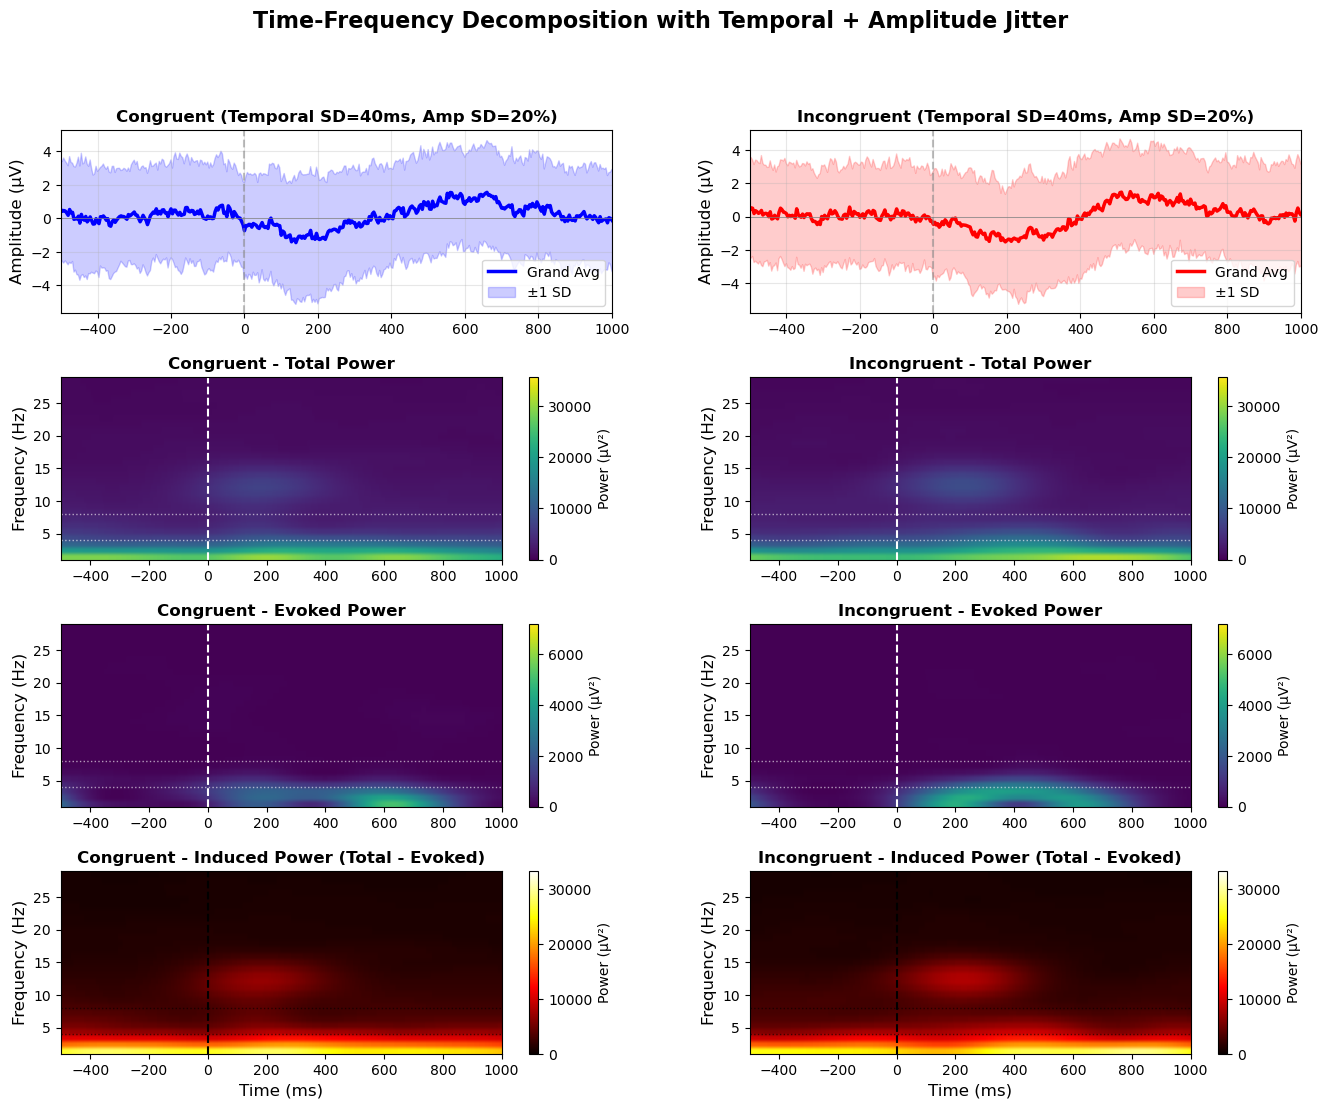

In [35]:
# Time-Frequency parameters
freqs = np.arange(1, 30, 1)  # 1-30 Hz
n_cycles = freqs / 2.0

def compute_tfr_trial(signal, freqs, n_cycles, sfreq):
    """Compute TFR for a single trial"""
    tfr = np.zeros((len(freqs), len(signal)))
    for idx, (freq, n_cycle) in enumerate(zip(freqs, n_cycles)):
        wavelet_duration = min(3 * n_cycle / freq, 0.5)
        wavelet_time = np.arange(-wavelet_duration, wavelet_duration, 1/sfreq)
        wavelet = np.exp(2j * np.pi * freq * wavelet_time) * \
                  np.exp(-wavelet_time**2 / (2 * (n_cycle / (2*np.pi*freq))**2))
        convolved = np.convolve(signal, wavelet, mode='same')
        tfr[idx, :] = np.abs(convolved) ** 2
    return tfr

print("Computing TFRs...")

# CONGRUENT: Evoked, Total, Induced
tfr_evoked_cong = compute_tfr_trial(grand_avg_congruent, freqs, n_cycles, sfreq)

tfr_total_cong = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    tfr_total_cong += compute_tfr_trial(trials_congruent[trial, :], freqs, n_cycles, sfreq)
tfr_total_cong /= n_trials

tfr_induced_cong = tfr_total_cong - tfr_evoked_cong

# INCONGRUENT: Evoked, Total, Induced
tfr_evoked_incong = compute_tfr_trial(grand_avg_incongruent, freqs, n_cycles, sfreq)

tfr_total_incong = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    tfr_total_incong += compute_tfr_trial(trials_incongruent[trial, :], freqs, n_cycles, sfreq)
tfr_total_incong /= n_trials

tfr_induced_incong = tfr_total_incong - tfr_evoked_incong

print("Done!")

# Compute SDs for grand averages
sd_cong = trials_congruent.std(axis=0)
sd_incong = trials_incongruent.std(axis=0)

# Plot
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(4, 2, hspace=0.35, wspace=0.25)

# Row 1: Grand averages
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(times * 1000, grand_avg_congruent, 'b', linewidth=2.5, label='Grand Avg')
ax1.fill_between(times * 1000, grand_avg_congruent - sd_cong, grand_avg_congruent + sd_cong,
                  color='b', alpha=0.2, label='±1 SD')
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlim([-500, 1000])
ax1.set_ylabel('Amplitude (µV)', fontsize=12)
ax1.set_title(f'Congruent (Temporal SD={jitter_sd_congruent*1000:.0f}ms, Amp SD={amplitude_jitter_congruent*100:.0f}%)', fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(times * 1000, grand_avg_incongruent, 'r', linewidth=2.5, label='Grand Avg')
ax2.fill_between(times * 1000, grand_avg_incongruent - sd_incong, grand_avg_incongruent + sd_incong,
                  color='r', alpha=0.2, label='±1 SD')
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_xlim([-500, 1000])
ax2.set_ylabel('Amplitude (µV)', fontsize=12)
ax2.set_title(f'Incongruent (Temporal SD={jitter_sd_incongruent*1000:.0f}ms, Amp SD={amplitude_jitter_incongruent*100:.0f}%)', fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

# Row 2: Total Power
vmax_total = max(tfr_total_cong.max(), tfr_total_incong.max())
ax3 = fig.add_subplot(gs[1, 0])
im3 = ax3.imshow(tfr_total_cong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_total, cmap='viridis')
ax3.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax3.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax3.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax3.set_xlim([-500, 1000])
ax3.set_ylabel('Frequency (Hz)', fontsize=12)
ax3.set_title('Congruent - Total Power', fontweight='bold')
plt.colorbar(im3, ax=ax3, label='Power (µV²)')

ax4 = fig.add_subplot(gs[1, 1])
im4 = ax4.imshow(tfr_total_incong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_total, cmap='viridis')
ax4.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax4.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax4.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax4.set_xlim([-500, 1000])
ax4.set_ylabel('Frequency (Hz)', fontsize=12)
ax4.set_title('Incongruent - Total Power', fontweight='bold')
plt.colorbar(im4, ax=ax4, label='Power (µV²)')

# Row 3: Evoked Power
vmax_evoked = max(tfr_evoked_cong.max(), tfr_evoked_incong.max())
ax5 = fig.add_subplot(gs[2, 0])
im5 = ax5.imshow(tfr_evoked_cong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_evoked, cmap='viridis')
ax5.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax5.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax5.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax5.set_xlim([-500, 1000])
ax5.set_ylabel('Frequency (Hz)', fontsize=12)
ax5.set_title('Congruent - Evoked Power', fontweight='bold')
plt.colorbar(im5, ax=ax5, label='Power (µV²)')

ax6 = fig.add_subplot(gs[2, 1])
im6 = ax6.imshow(tfr_evoked_incong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_evoked, cmap='viridis')
ax6.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax6.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax6.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax6.set_xlim([-500, 1000])
ax6.set_ylabel('Frequency (Hz)', fontsize=12)
ax6.set_title('Incongruent - Evoked Power', fontweight='bold')
plt.colorbar(im6, ax=ax6, label='Power (µV²)')

# Row 4: Induced Power - SAME SCALE
vmax_induced = max(tfr_induced_cong.max(), tfr_induced_incong.max())
ax7 = fig.add_subplot(gs[3, 0])
im7 = ax7.imshow(tfr_induced_cong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_induced, cmap='hot')
ax7.axvline(0, color='black', linestyle='--', linewidth=1.5)
ax7.axhline(4, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax7.axhline(8, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax7.set_xlim([-500, 1000])
ax7.set_xlabel('Time (ms)', fontsize=12)
ax7.set_ylabel('Frequency (Hz)', fontsize=12)
ax7.set_title('Congruent - Induced Power (Total - Evoked)', fontweight='bold')
plt.colorbar(im7, ax=ax7, label='Power (µV²)')

ax8 = fig.add_subplot(gs[3, 1])
im8 = ax8.imshow(tfr_induced_incong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_induced, cmap='hot')
ax8.axvline(0, color='black', linestyle='--', linewidth=1.5)
ax8.axhline(4, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax8.axhline(8, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax8.set_xlim([-500, 1000])
ax8.set_xlabel('Time (ms)', fontsize=12)
ax8.set_ylabel('Frequency (Hz)', fontsize=12)
ax8.set_title('Incongruent - Induced Power (Total - Evoked)', fontweight='bold')
plt.colorbar(im8, ax=ax8, label='Power (µV²)')

plt.suptitle('Time-Frequency Decomposition with Temporal + Amplitude Jitter', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

Applying STOCHASTIC Woody filter (1000 runs)...
Run 0/1000: New best corr = 0.1980

Best correlation: 0.2114
Lag range: [-75, 93] samples
Lag std: 29.02 samples

Congruent: Best correlation = 0.2114
Run 0/1000: New best corr = 0.2091

Best correlation: 0.2109
Lag range: [-80, 86] samples
Lag std: 29.37 samples

Incongruent: Best correlation = 0.2109

Done!

=== LAG ESTIMATION ACCURACY ===
Congruent MAE: 18.83 samples (37.7ms)
Incongruent MAE: 20.71 samples (41.4ms)


/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_3848/3551465196.py:147: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


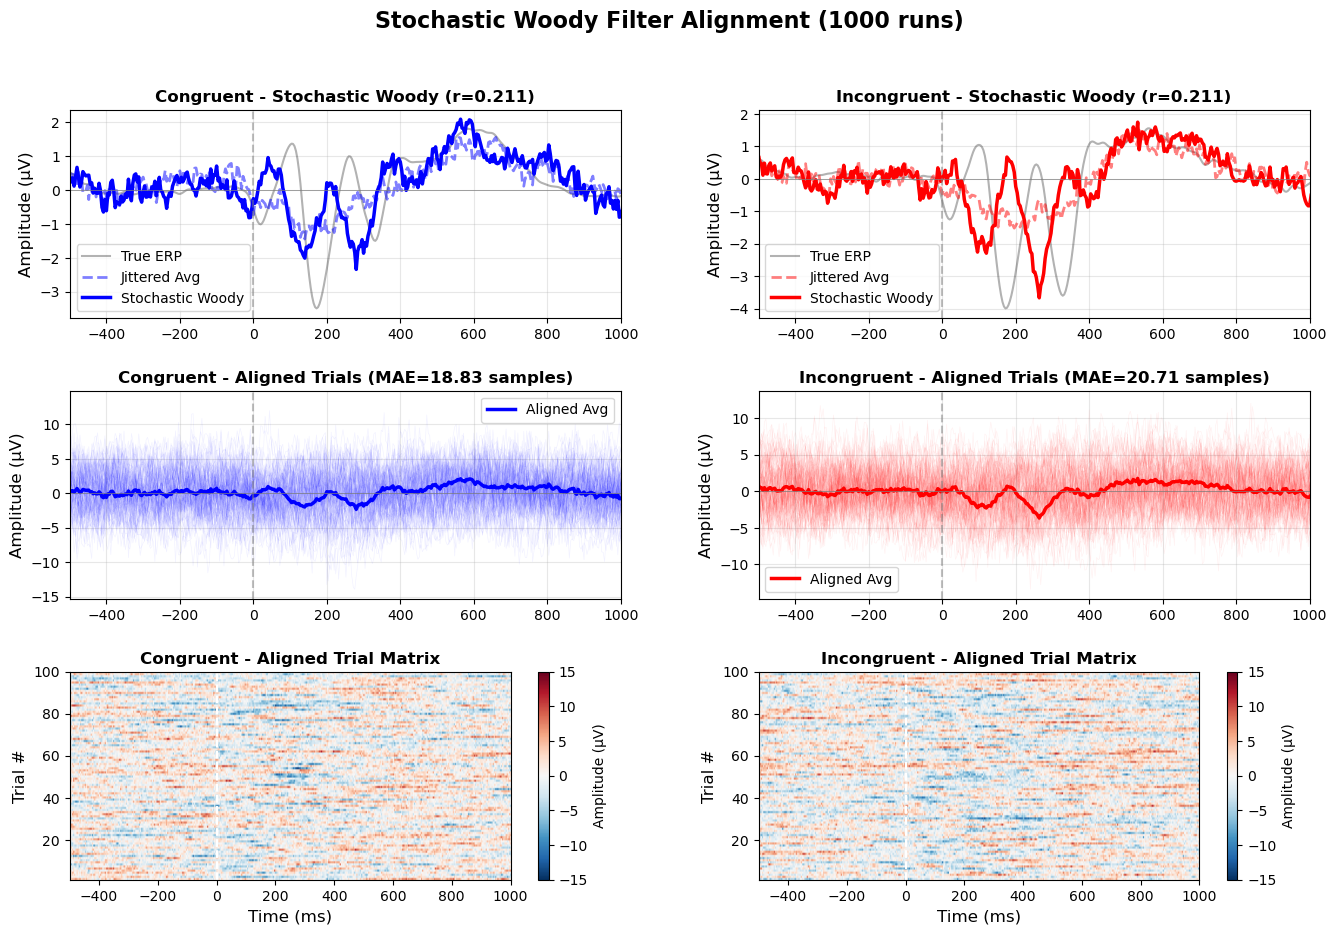

In [36]:
from woody_filter import woody_stochastic

print("Applying STOCHASTIC Woody filter (1000 runs)...")

# Apply Stochastic Woody filter to CONGRUENT trials
trials_cong_transposed = trials_congruent.T  # Shape: (n_timepoints, n_trials)

aligned_avg_cong, detected_lags_cong, corr_cong = woody_stochastic(
    trials_cong_transposed,
    n_runs=1000,
    max_lag_init=50,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased',
    max_shift=50,
    verbose=True
)

print(f"\nCongruent: Best correlation = {corr_cong:.4f}")

# Reconstruct individual aligned congruent trials
aligned_trials_cong = np.zeros_like(trials_congruent)
for i in range(n_trials):
    lag = detected_lags_cong[i]
    if lag > 0 and lag < n_times:
        aligned_trials_cong[i, lag:] = trials_congruent[i, :-lag]
    elif lag < 0 and -lag < n_times:
        aligned_trials_cong[i, :lag] = trials_congruent[i, -lag:]
    else:
        aligned_trials_cong[i, :] = trials_congruent[i, :]

# Apply Stochastic Woody filter to INCONGRUENT trials
trials_incong_transposed = trials_incongruent.T

aligned_avg_incong, detected_lags_incong, corr_incong = woody_stochastic(
    trials_incong_transposed,
    n_runs=1000,
    max_lag_init=50,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased',
    max_shift=50,
    verbose=True
)

print(f"\nIncongruent: Best correlation = {corr_incong:.4f}")

# Reconstruct individual aligned incongruent trials
aligned_trials_incong = np.zeros_like(trials_incongruent)
for i in range(n_trials):
    lag = detected_lags_incong[i]
    if lag > 0 and lag < n_times:
        aligned_trials_incong[i, lag:] = trials_incongruent[i, :-lag]
    elif lag < 0 and -lag < n_times:
        aligned_trials_incong[i, :lag] = trials_incongruent[i, -lag:]
    else:
        aligned_trials_incong[i, :] = trials_incongruent[i, :]

print("\nDone!")

# Compute lag estimation accuracy
lag_error_cong = np.abs(np.array(jitters_congruent) * sfreq - detected_lags_cong)
lag_error_incong = np.abs(np.array(jitters_incongruent) * sfreq - detected_lags_incong)

print(f"\n=== LAG ESTIMATION ACCURACY ===")
print(f"Congruent MAE: {lag_error_cong.mean():.2f} samples ({lag_error_cong.mean()*2:.1f}ms)")
print(f"Incongruent MAE: {lag_error_incong.mean():.2f} samples ({lag_error_incong.mean()*2:.1f}ms)")

# Plot
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 2, hspace=0.35, wspace=0.25)

# Row 1: Aligned grand averages comparison
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(times * 1000, erp_congruent, 'k', linewidth=1.5, alpha=0.3, label='True ERP')
ax1.plot(times * 1000, grand_avg_congruent, 'b--', linewidth=2, alpha=0.5, label='Jittered Avg')
ax1.plot(times * 1000, aligned_avg_cong, 'b', linewidth=2.5, label='Stochastic Woody')
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlim([-500, 1000])
ax1.set_ylabel('Amplitude (µV)', fontsize=12)
ax1.set_title(f'Congruent - Stochastic Woody (r={corr_cong:.3f})', fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(times * 1000, erp_incongruent, 'k', linewidth=1.5, alpha=0.3, label='True ERP')
ax2.plot(times * 1000, grand_avg_incongruent, 'r--', linewidth=2, alpha=0.5, label='Jittered Avg')
ax2.plot(times * 1000, aligned_avg_incong, 'r', linewidth=2.5, label='Stochastic Woody')
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_xlim([-500, 1000])
ax2.set_ylabel('Amplitude (µV)', fontsize=12)
ax2.set_title(f'Incongruent - Stochastic Woody (r={corr_incong:.3f})', fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

# Row 2: Aligned single trials
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(times * 1000, aligned_trials_cong.T, 'b', alpha=0.05, linewidth=0.5)
ax3.plot(times * 1000, aligned_avg_cong, 'b', linewidth=2.5, label='Aligned Avg')
ax3.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax3.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax3.set_xlim([-500, 1000])
ax3.set_ylabel('Amplitude (µV)', fontsize=12)
ax3.set_title(f'Congruent - Aligned Trials (MAE={lag_error_cong.mean():.2f} samples)', fontweight='bold')
ax3.legend()
ax3.grid(alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.plot(times * 1000, aligned_trials_incong.T, 'r', alpha=0.05, linewidth=0.5)
ax4.plot(times * 1000, aligned_avg_incong, 'r', linewidth=2.5, label='Aligned Avg')
ax4.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax4.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax4.set_xlim([-500, 1000])
ax4.set_ylabel('Amplitude (µV)', fontsize=12)
ax4.set_title(f'Incongruent - Aligned Trials (MAE={lag_error_incong.mean():.2f} samples)', fontweight='bold')
ax4.legend()
ax4.grid(alpha=0.3)

# Row 3: Trial matrices
ax5 = fig.add_subplot(gs[2, 0])
im5 = ax5.imshow(aligned_trials_cong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, 1, n_trials],
                 cmap='RdBu_r', vmin=-15, vmax=15)
ax5.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax5.set_xlim([-500, 1000])
ax5.set_xlabel('Time (ms)', fontsize=12)
ax5.set_ylabel('Trial #', fontsize=12)
ax5.set_title('Congruent - Aligned Trial Matrix', fontweight='bold')
plt.colorbar(im5, ax=ax5, label='Amplitude (µV)')

ax6 = fig.add_subplot(gs[2, 1])
im6 = ax6.imshow(aligned_trials_incong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, 1, n_trials],
                 cmap='RdBu_r', vmin=-15, vmax=15)
ax6.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax6.set_xlim([-500, 1000])
ax6.set_xlabel('Time (ms)', fontsize=12)
ax6.set_ylabel('Trial #', fontsize=12)
ax6.set_title('Incongruent - Aligned Trial Matrix', fontweight='bold')
plt.colorbar(im6, ax=ax6, label='Amplitude (µV)')

plt.suptitle('Stochastic Woody Filter Alignment (1000 runs)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

Applying Stochastic Woody filter (1000 runs)...

Run 0/1000: New best corr = 0.1993

Best correlation: 0.2117
Lag range: [-99, 69] samples
Lag std: 33.06 samples

Congruent: Best correlation = 0.2117
Run 0/1000: New best corr = 0.2010
Run 100/1000: New best corr = 0.2083

Best correlation: 0.2112
Lag range: [-74, 90] samples
Lag std: 28.03 samples

Incongruent: Best correlation = 0.2112



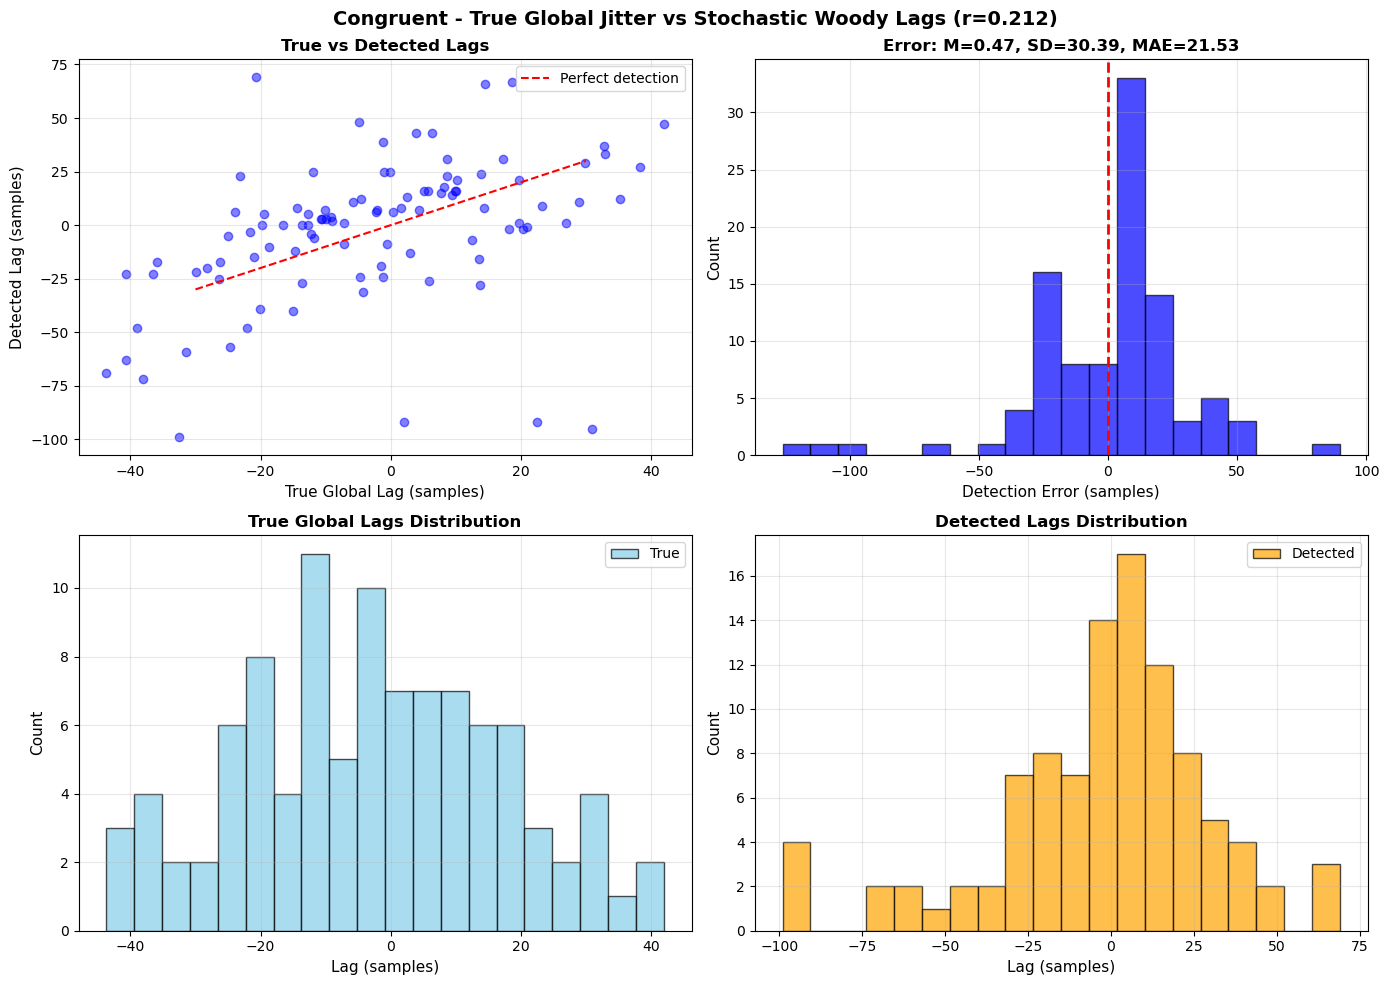

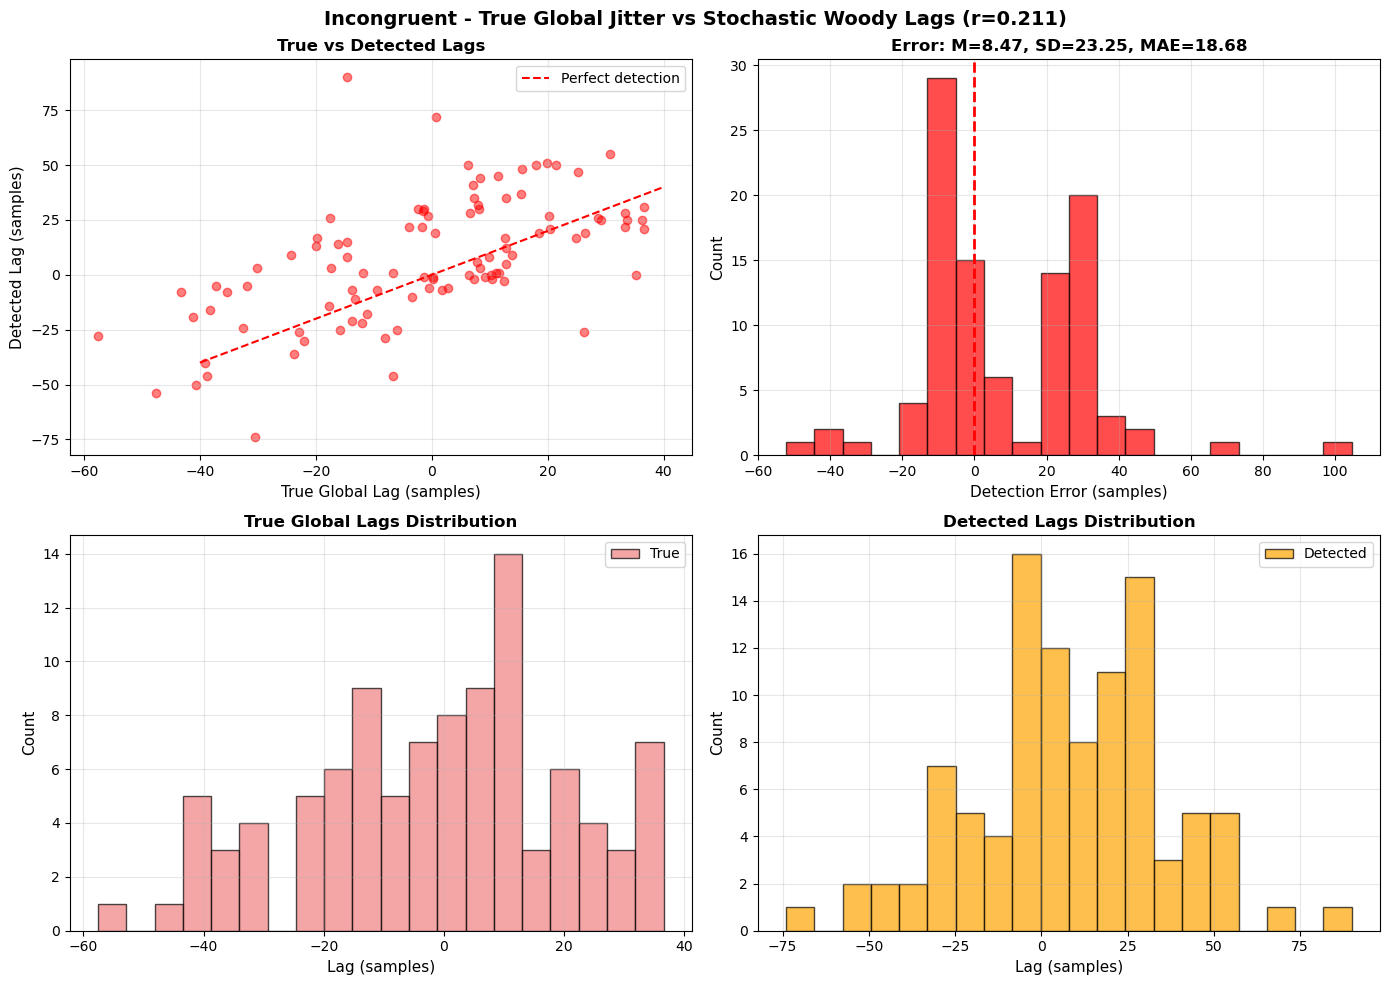


=== STOCHASTIC WOODY PERFORMANCE ===
Congruent:
  Correlation: 0.2117
  MAE: 21.53 samples (43.1ms)
  Bias: 0.47 samples

Incongruent:
  Correlation: 0.2112
  MAE: 18.68 samples (37.4ms)
  Bias: 8.47 samples


In [37]:
from woody_filter import woody_stochastic

print("Applying Stochastic Woody filter (1000 runs)...\n")

# Apply STOCHASTIC Woody filter to both conditions
trials_cong_transposed = trials_congruent.T
aligned_avg_cong, detected_lags_cong, corr_cong = woody_stochastic(
    trials_cong_transposed, 
    n_runs=1000,
    max_lag_init=50,
    tol=0.1, 
    max_it=100, 
    est_mthd='woody', 
    xcorr_mthd='unbiased',
    max_shift=50,
    verbose=True
)

print(f"\nCongruent: Best correlation = {corr_cong:.4f}")

trials_incong_transposed = trials_incongruent.T
aligned_avg_incong, detected_lags_incong, corr_incong = woody_stochastic(
    trials_incong_transposed,
    n_runs=1000,
    max_lag_init=50,
    tol=0.1,
    max_it=100,
    est_mthd='woody',
    xcorr_mthd='unbiased',
    max_shift=50,
    verbose=True
)

print(f"\nIncongruent: Best correlation = {corr_incong:.4f}\n")

# Convert true global jitters to samples
true_lags_cong_samples = jitters_congruent * sfreq
true_lags_incong_samples = jitters_incongruent * sfreq

# Compare for CONGRUENT
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'Congruent - True Global Jitter vs Stochastic Woody Lags (r={corr_cong:.3f})', 
             fontsize=14, fontweight='bold')

axes[0, 0].scatter(true_lags_cong_samples, detected_lags_cong, alpha=0.5, color='blue')
axes[0, 0].plot([-30, 30], [-30, 30], 'r--', label='Perfect detection')
axes[0, 0].set_xlabel('True Global Lag (samples)', fontsize=11)
axes[0, 0].set_ylabel('Detected Lag (samples)', fontsize=11)
axes[0, 0].set_title('True vs Detected Lags', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

error_cong = detected_lags_cong - true_lags_cong_samples
axes[0, 1].hist(error_cong, bins=20, edgecolor='black', color='blue', alpha=0.7)
axes[0, 1].axvline(0, color='r', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('Detection Error (samples)', fontsize=11)
axes[0, 1].set_ylabel('Count', fontsize=11)
axes[0, 1].set_title(f'Error: M={error_cong.mean():.2f}, SD={error_cong.std():.2f}, MAE={np.abs(error_cong).mean():.2f}', 
                     fontweight='bold')
axes[0, 1].grid(alpha=0.3)

axes[1, 0].hist(true_lags_cong_samples, bins=20, edgecolor='black', alpha=0.7, label='True', color='skyblue')
axes[1, 0].set_xlabel('Lag (samples)', fontsize=11)
axes[1, 0].set_ylabel('Count', fontsize=11)
axes[1, 0].set_title('True Global Lags Distribution', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

axes[1, 1].hist(detected_lags_cong, bins=20, edgecolor='black', alpha=0.7, label='Detected', color='orange')
axes[1, 1].set_xlabel('Lag (samples)', fontsize=11)
axes[1, 1].set_ylabel('Count', fontsize=11)
axes[1, 1].set_title('Detected Lags Distribution', fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Compare for INCONGRUENT
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'Incongruent - True Global Jitter vs Stochastic Woody Lags (r={corr_incong:.3f})', 
             fontsize=14, fontweight='bold')

axes[0, 0].scatter(true_lags_incong_samples, detected_lags_incong, alpha=0.5, color='red')
axes[0, 0].plot([-40, 40], [-40, 40], 'r--', label='Perfect detection')
axes[0, 0].set_xlabel('True Global Lag (samples)', fontsize=11)
axes[0, 0].set_ylabel('Detected Lag (samples)', fontsize=11)
axes[0, 0].set_title('True vs Detected Lags', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

error_incong = detected_lags_incong - true_lags_incong_samples
axes[0, 1].hist(error_incong, bins=20, edgecolor='black', color='red', alpha=0.7)
axes[0, 1].axvline(0, color='r', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('Detection Error (samples)', fontsize=11)
axes[0, 1].set_ylabel('Count', fontsize=11)
axes[0, 1].set_title(f'Error: M={error_incong.mean():.2f}, SD={error_incong.std():.2f}, MAE={np.abs(error_incong).mean():.2f}', 
                     fontweight='bold')
axes[0, 1].grid(alpha=0.3)

axes[1, 0].hist(true_lags_incong_samples, bins=20, edgecolor='black', alpha=0.7, label='True', color='lightcoral')
axes[1, 0].set_xlabel('Lag (samples)', fontsize=11)
axes[1, 0].set_ylabel('Count', fontsize=11)
axes[1, 0].set_title('True Global Lags Distribution', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

axes[1, 1].hist(detected_lags_incong, bins=20, edgecolor='black', alpha=0.7, label='Detected', color='orange')
axes[1, 1].set_xlabel('Lag (samples)', fontsize=11)
axes[1, 1].set_ylabel('Count', fontsize=11)
axes[1, 1].set_title('Detected Lags Distribution', fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n=== STOCHASTIC WOODY PERFORMANCE ===")
print(f"Congruent:")
print(f"  Correlation: {corr_cong:.4f}")
print(f"  MAE: {np.abs(error_cong).mean():.2f} samples ({np.abs(error_cong).mean()*2:.1f}ms)")
print(f"  Bias: {error_cong.mean():.2f} samples")
print(f"\nIncongruent:")
print(f"  Correlation: {corr_incong:.4f}")
print(f"  MAE: {np.abs(error_incong).mean():.2f} samples ({np.abs(error_incong).mean()*2:.1f}ms)")
print(f"  Bias: {error_incong.mean():.2f} samples")

Computing TFRs on ALIGNED data...
Done!


/var/folders/rr/gnh_10j903n2jfm31kmd5hfh0000gp/T/ipykernel_3848/1089601161.py:143: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


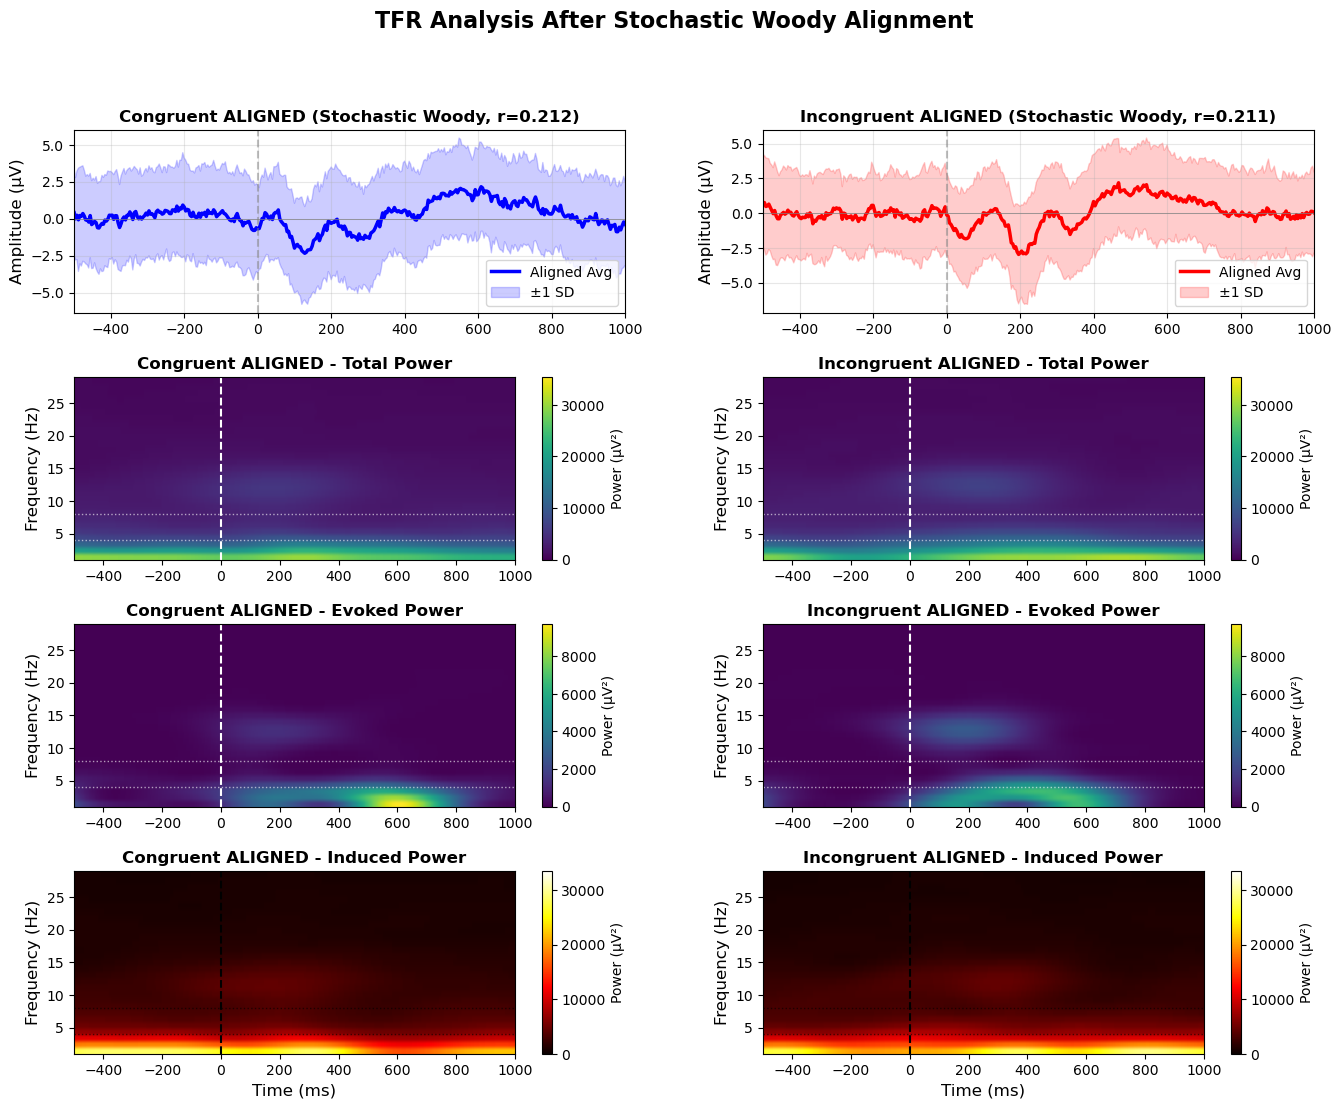

In [39]:
# Compute SDs for aligned trials
sd_aligned_cong = aligned_trials_cong.std(axis=0)
sd_aligned_incong = aligned_trials_incong.std(axis=0)

print("Computing TFRs on ALIGNED data...")

# Time-Frequency Analysis on ALIGNED data (1-30 Hz)
freqs = np.arange(1, 30, 1)
n_cycles = freqs / 2.0

# CONGRUENT ALIGNED: Evoked, Total, Induced
tfr_evoked_aligned_cong = compute_tfr_trial(aligned_avg_cong, freqs, n_cycles, sfreq)

tfr_total_aligned_cong = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    tfr_total_aligned_cong += compute_tfr_trial(aligned_trials_cong[trial, :], freqs, n_cycles, sfreq)
tfr_total_aligned_cong /= n_trials

tfr_induced_aligned_cong = tfr_total_aligned_cong - tfr_evoked_aligned_cong

# INCONGRUENT ALIGNED: Evoked, Total, Induced
tfr_evoked_aligned_incong = compute_tfr_trial(aligned_avg_incong, freqs, n_cycles, sfreq)

tfr_total_aligned_incong = np.zeros((len(freqs), len(times)))
for trial in range(n_trials):
    tfr_total_aligned_incong += compute_tfr_trial(aligned_trials_incong[trial, :], freqs, n_cycles, sfreq)
tfr_total_aligned_incong /= n_trials

tfr_induced_aligned_incong = tfr_total_aligned_incong - tfr_evoked_aligned_incong

print("Done!")

# Plot
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(4, 2, hspace=0.35, wspace=0.25)

# Row 1: Grand averages ALIGNED
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(times * 1000, aligned_avg_cong, 'b', linewidth=2.5, label='Aligned Avg')
ax1.fill_between(times * 1000, aligned_avg_cong - sd_aligned_cong, 
                 aligned_avg_cong + sd_aligned_cong, color='b', alpha=0.2, label='±1 SD')
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax1.set_xlim([-500, 1000])
ax1.set_ylabel('Amplitude (µV)', fontsize=12)
ax1.set_title(f'Congruent ALIGNED (Stochastic Woody, r={corr_cong:.3f})', fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(times * 1000, aligned_avg_incong, 'r', linewidth=2.5, label='Aligned Avg')
ax2.fill_between(times * 1000, aligned_avg_incong - sd_aligned_incong,
                 aligned_avg_incong + sd_aligned_incong, color='r', alpha=0.2, label='±1 SD')
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='-', linewidth=0.5)
ax2.set_xlim([-500, 1000])
ax2.set_ylabel('Amplitude (µV)', fontsize=12)
ax2.set_title(f'Incongruent ALIGNED (Stochastic Woody, r={corr_incong:.3f})', fontweight='bold')
ax2.legend()
ax2.grid(alpha=0.3)

# Row 2: Total Power ALIGNED
vmax_total_aligned = max(tfr_total_aligned_cong.max(), tfr_total_aligned_incong.max())
ax3 = fig.add_subplot(gs[1, 0])
im3 = ax3.imshow(tfr_total_aligned_cong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_total_aligned, cmap='viridis')
ax3.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax3.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax3.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax3.set_xlim([-500, 1000])
ax3.set_ylabel('Frequency (Hz)', fontsize=12)
ax3.set_title('Congruent ALIGNED - Total Power', fontweight='bold')
plt.colorbar(im3, ax=ax3, label='Power (µV²)')

ax4 = fig.add_subplot(gs[1, 1])
im4 = ax4.imshow(tfr_total_aligned_incong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_total_aligned, cmap='viridis')
ax4.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax4.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax4.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax4.set_xlim([-500, 1000])
ax4.set_ylabel('Frequency (Hz)', fontsize=12)
ax4.set_title('Incongruent ALIGNED - Total Power', fontweight='bold')
plt.colorbar(im4, ax=ax4, label='Power (µV²)')

# Row 3: Evoked Power ALIGNED
vmax_evoked_aligned = max(tfr_evoked_aligned_cong.max(), tfr_evoked_aligned_incong.max())
ax5 = fig.add_subplot(gs[2, 0])
im5 = ax5.imshow(tfr_evoked_aligned_cong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_evoked_aligned, cmap='viridis')
ax5.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax5.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax5.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax5.set_xlim([-500, 1000])
ax5.set_ylabel('Frequency (Hz)', fontsize=12)
ax5.set_title('Congruent ALIGNED - Evoked Power', fontweight='bold')
plt.colorbar(im5, ax=ax5, label='Power (µV²)')

ax6 = fig.add_subplot(gs[2, 1])
im6 = ax6.imshow(tfr_evoked_aligned_incong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_evoked_aligned, cmap='viridis')
ax6.axvline(0, color='white', linestyle='--', linewidth=1.5)
ax6.axhline(4, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax6.axhline(8, color='white', linestyle=':', linewidth=1, alpha=0.6)
ax6.set_xlim([-500, 1000])
ax6.set_ylabel('Frequency (Hz)', fontsize=12)
ax6.set_title('Incongruent ALIGNED - Evoked Power', fontweight='bold')
plt.colorbar(im6, ax=ax6, label='Power (µV²)')

# Row 4: Induced Power ALIGNED - SAME SCALE
vmax_induced_aligned = max(tfr_induced_aligned_cong.max(), tfr_induced_aligned_incong.max())
ax7 = fig.add_subplot(gs[3, 0])
im7 = ax7.imshow(tfr_induced_aligned_cong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_induced_aligned, cmap='hot')
ax7.axvline(0, color='black', linestyle='--', linewidth=1.5)
ax7.axhline(4, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax7.axhline(8, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax7.set_xlim([-500, 1000])
ax7.set_xlabel('Time (ms)', fontsize=12)
ax7.set_ylabel('Frequency (Hz)', fontsize=12)
ax7.set_title('Congruent ALIGNED - Induced Power', fontweight='bold')
plt.colorbar(im7, ax=ax7, label='Power (µV²)')

ax8 = fig.add_subplot(gs[3, 1])
im8 = ax8.imshow(tfr_induced_aligned_incong, aspect='auto', origin='lower',
                 extent=[times[0] * 1000, times[-1] * 1000, freqs[0], freqs[-1]],
                 vmin=0, vmax=vmax_induced_aligned, cmap='hot')
ax8.axvline(0, color='black', linestyle='--', linewidth=1.5)
ax8.axhline(4, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax8.axhline(8, color='black', linestyle=':', linewidth=1, alpha=0.6)
ax8.set_xlim([-500, 1000])
ax8.set_xlabel('Time (ms)', fontsize=12)
ax8.set_ylabel('Frequency (Hz)', fontsize=12)
ax8.set_title('Incongruent ALIGNED - Induced Power', fontweight='bold')
plt.colorbar(im8, ax=ax8, label='Power (µV²)')

plt.suptitle('TFR Analysis After Stochastic Woody Alignment', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

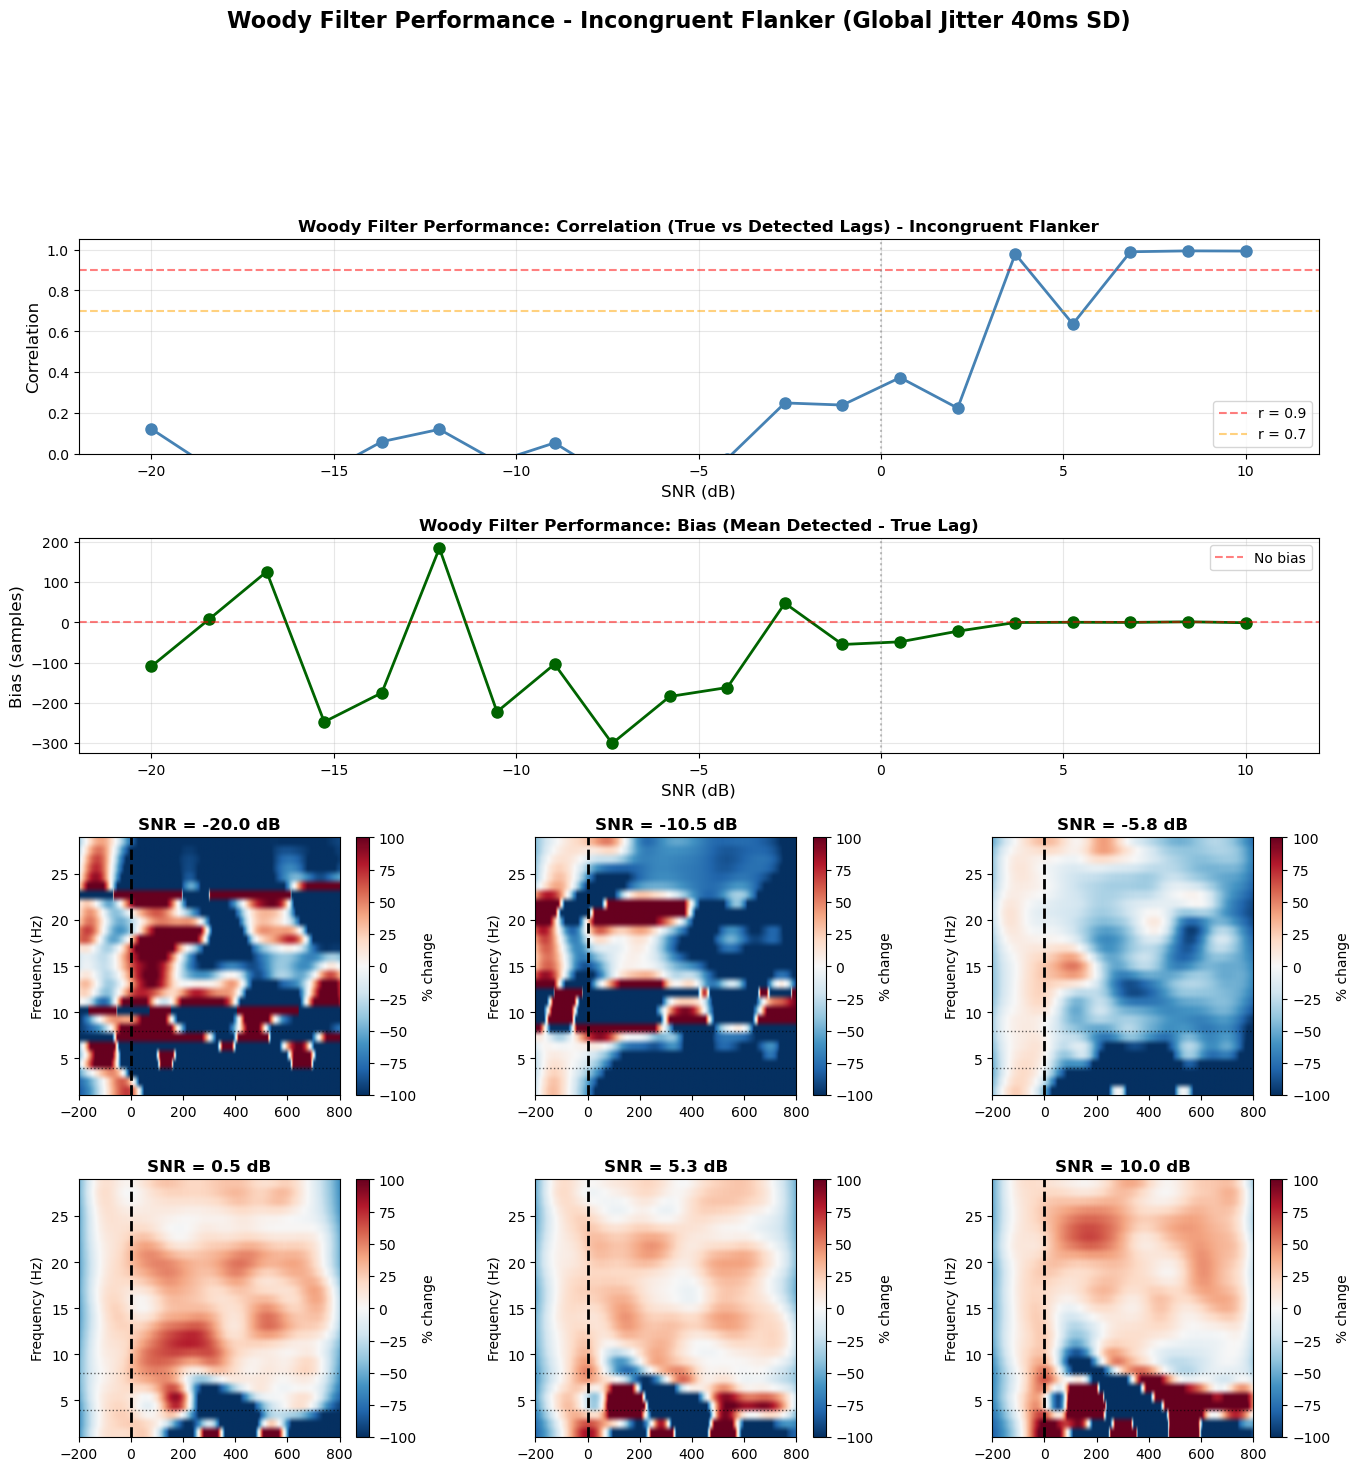

In [ ]:
/

In [40]:
# # Compute signal RMS for INCONGRUENT condition
# signal_rms = np.sqrt(np.mean(erp_incongruent**2))

# # Selected SNR levels to plot
# snr_levels_to_plot = [-20, -10, -5, 0, 5, 10]
# freqs_tfr = np.arange(1, 30, 1)
# n_cycles_tfr = freqs_tfr / 2.0
# n_trials_snr = 100
# jitter_sd = jitter_sd_incongruent  # 40ms SD

# # Baseline window
# baseline_window = (times >= -0.2) & (times < 0)

# # Create figure
# fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
# axes = axes.flatten()

# for idx, snr_db in enumerate(snr_levels_to_plot):
#     ax = axes[idx]
    
#     # Calculate noise amplitude
#     snr_linear = 10**(snr_db / 20)
#     noise_amp = signal_rms / snr_linear
    
#     # Generate trials WITHOUT alignment
#     trials_noisy = np.zeros((n_trials_snr, n_times))
    
#     for trial in range(n_trials_snr):
#         # Global jitter
#         global_jitter = np.random.normal(0, jitter_sd)
        
#         # Generate all components with same jitter
#         n1 = n1_amplitude * np.exp(-0.5 * ((times - (n1_time + global_jitter)) / n1_width) ** 2)
#         n2 = n2_amplitude_incongruent * np.exp(-0.5 * ((times - (n2_time + global_jitter)) / n2_width) ** 2)
#         p3 = p3_amplitude_incongruent * np.exp(-0.5 * ((times - (p3_time_incongruent + global_jitter)) / p3_width) ** 2)
#         ln = ln_amplitude_incongruent * np.exp(-0.5 * ((times - (ln_time + global_jitter)) / ln_width) ** 2)
        
#         noise = generate_pink_noise(n_times) * noise_amp
#         trials_noisy[trial, :] = n1 + n2 + p3 + ln + noise
    
#     # NO Woody filtering - use raw trials
#     grand_avg_raw = trials_noisy.mean(axis=0)
    
#     # Compute TFRs
#     tfr_evoked_raw = compute_tfr_trial(grand_avg_raw, freqs_tfr, n_cycles_tfr, sfreq)
    
#     tfr_total_raw = np.zeros((len(freqs_tfr), len(times)))
#     for trial in range(n_trials_snr):
#         tfr_total_raw += compute_tfr_trial(trials_noisy[trial, :], freqs_tfr, n_cycles_tfr, sfreq)
#     tfr_total_raw /= n_trials_snr
    
#     tfr_induced_raw = tfr_total_raw - tfr_evoked_raw
    
#     # Baseline correction (percent change)
#     baseline_mean = tfr_induced_raw[:, baseline_window].mean(axis=1, keepdims=True)
#     tfr_induced_baseline = (tfr_induced_raw - baseline_mean) / baseline_mean * 100
    
#     # Plot
#     im = ax.imshow(tfr_induced_baseline, aspect='auto', origin='lower',
#                    extent=[tmin * 1000, tmax * 1000, freqs_tfr[0], freqs_tfr[-1]],
#                    cmap='RdBu_r', vmin=-100, vmax=100)
#     ax.axvline(0, color='black', linestyle='--', linewidth=2)
#     ax.axhline(4, color='black', linestyle=':', linewidth=1, alpha=0.6)
#     ax.axhline(8, color='black', linestyle=':', linewidth=1, alpha=0.6)
#     ax.set_title(f'SNR = {snr_db} dB', fontweight='bold')
#     ax.set_ylabel('Frequency (Hz)')
    
#     if idx >= 3:
#         ax.set_xlabel('Time (ms)')
    
#     plt.colorbar(im, ax=ax, label='% change')

# plt.suptitle('NON-ALIGNED: Induced Power - Incongruent Flanker (Global Jitter 40ms SD)', fontsize=14, y=0.995, fontweight='bold')
# plt.tight_layout()
# plt.show()